# 08 - Make the final Catalogue

From the calibrated frame extract the photometry of the stars using Sextractor<br>
Apply light correction based on the results of the notebook 7.b<br>
Save the final catalogue combining Pycavi and Gaia photometries<br>

Done:<br>
* Sextractor running over the calibrated frame
* Read the catalogue (fits table)
* Read the Gaia catalogue
* Cross match the catalogues
* Create the final catalogue
* Create a merged catalogue of the sextractor images
* Clean the merged sextractor catalogue before comparing with Gaia
* First crossmatch the sextractor catalogues, then cross with Gaia
* Pack the code into the cell
* Add the zero point depending on the filter
* Validate r filter against SkyMapper
* Modify the zp cal notebook to save additional Gaia parameters
* Save the Gaia query as a raw query, create the clean versions as a different files, or add an additional column that defines if the source in each row is used in the clean version.
* Get the zp from the frame itself

ToDo:<br>
* Validate NB filter against VPHAS
* Add the sextractor parameters for the catalogue within the notebook
* For the same reason, minimize the sextractor default parameters. Think in the use for scamp
* Add a header for the fits catalogue. Inspire in vphas catalogues headers.

Notes:<br>
* Modified the papi_sextractor to allows the default parameter file to incorporated the position of the stars (XY_IMAGE, ALPHA/DELTA_J2000), as well as the Petro flux and mag.
* Petro mags shows the slopeless results when comparing Sextractor and Gaia mags.
* The zero points for photometry depend on the filter only: 21.40 for r_SDSS and 21.50 for NB in AB system.
* The merged catalogue includes the r_SDSS and NB filters, together with the Gaia data.
* The pycavi ra and dec were mean combined

In [4]:
import os
import sys
import logging

import numpy as np
import pandas as pd

from astropy.io import fits
from astropy.table import Table, hstack

from astropy.coordinates import SkyCoord
import astropy.units as u

sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production
from pycavi import pycavi_tools, pycavi_astromatic_tools
from pycavi.pycavi_zpcal import get_files_dict

import matplotlib.pyplot as plt

In [ ]:
def getzpfromframe(framepath):
    hdr = fits.getheader(framepath)
    return hdr['HIERARCH ESO PYCAVI QC MAGZP']
    

In [2]:
def load_catalogue(catalogue_path, extnumber=2):
    # the extension name varies with the catalogue. For the sextractor output, the extnumber is two
    hdul = fits.open(catalogue_path)
    table_data = hdul[extnumber].data
    hdul.close()
    output_table = Table(table_data)
    return output_table
    

In [3]:
def crossmatch_catalogues(cat_1, cat_2, max_sep=1.0,
                          radec_tag_1=['raj2000', 'dej2000'], 
                          radec_tag_2=['raj2000', 'dej2000']):
    """
    Perform a crossmatch between catalogue 1 and catalogue 2.
    Both catalogue must be Astropy Table objects.
    
    Parameters:
        cat_1: Table with the catalogue to cross match
        cat_2: Table with the catalogue to cross match
        max_sep: maximum tolerance in arcsec between two sources to match. Default 1 arcsec
        radec_tag_1: list with the tags for the ra and dec in catalogue 1
        radec_tag_2: list with the tags for the ra and dec in catalogue 2
        
    Output:
        table_matched: Astropy Table with the cross matched sources.
    """
    # first check which catalogue is the longer
    # assing the catalogues and tag acordingly
    if len(cat_1) >= len(cat_2):
        cat_long = cat_1
        cat_short = cat_2
        radec_long = radec_tag_1
        radec_short = radec_tag_2
    else:
        cat_long = cat_2
        cat_short = cat_1
        radec_long = radec_tag_2
        radec_short = radec_tag_1
        
    # do the cross match
    skycoord_long = SkyCoord(ra=cat_long[radec_long[0]]*u.degree, dec=cat_long[radec_long[1]]*u.degree)
    skycoord_short = SkyCoord(ra=cat_short[radec_short[0]]*u.degree, dec=cat_short[radec_short[1]]*u.degree)
    
    max_sep_thresh = max_sep * u.arcsec
    idx, d2d, _ = skycoord_long.match_to_catalog_sky(skycoord_short)
    sep_constraint = d2d < max_sep_thresh

    matches_short = cat_short[idx[sep_constraint]]

    # create the combined catalogue
    table_short_matches = {}
    for col in cat_short.colnames:
        aux_arr = 1.0*np.arange(len(cat_long))
        aux_arr[:] = np.nan
        aux_arr[sep_constraint] = matches_short[col]
        table_short_matches[col] = aux_arr

    table_short_matches = Table(table_short_matches)
    table_matched = hstack([cat_long, table_short_matches])
    return table_matched


In [ ]:
def clean_merged_catalogue(merged_catalogue):
    """
    Clean the merged catalogue by removing sources that were not detected on all the catalogues.
    Average the celestial positions but keep the rest of columns untouched
    """
    # select the ra and dec columns from the input table
    ra = {}
    de = {}
    tags = []
    for col in merged_catalogue.colnames:
        if 'ALPHA_J2000' in col:
            tag = col[12:]  # the filter tag, eg, r_SDSS
            tags.append(tag)
            racol = 'ALPHA_J2000_'+tag
            decol = 'DELTA_J2000_'+tag
            ra[tag]=merged_catalogue[racol]
            de[tag]=merged_catalogue[decol]
    
    # remove the entries where there is a nan
    sel_nan = np.ones(len(merged_catalogue), dtype=bool)
    for tag in ra.keys():
        ra_data = ra[tag]
        sel_tag = np.isnan(ra_data)
        sel_nan = sel_nan & ~sel_tag
            
    # clean the catalogue
    clean_catalogue = merged_catalogue[sel_nan]
    
    # combine the ra and dec
    ra_comb = None
    de_comb = None
    for tag in tags:
        if ra_comb is None:
            ra_comb = clean_catalogue['ALPHA_J2000_'+tag]
            de_comb = clean_catalogue['DELTA_J2000_'+tag]
        else:
            ra_comb = np.vstack((ra_comb, clean_catalogue['ALPHA_J2000_'+tag])).T
            de_comb = np.vstack((de_comb, clean_catalogue['DELTA_J2000_'+tag])).T
    ra_mean = np.mean(ra_comb, axis=1)
    de_mean = np.mean(de_comb, axis=1)
    
    # remove alpha/delta j2000 columns
    clean_catalogue.remove_columns(['ALPHA_J2000_'+tag for tag in tags])
    clean_catalogue.remove_columns(['DELTA_J2000_'+tag for tag in tags])
    
    # add mean alpha and delta
    clean_catalogue['raj2000'] = ra_mean
    clean_catalogue['dej2000'] = de_mean
    
    return clean_catalogue

In [6]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
images_to_check = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        images_to_check.append(zpcal_dict[observation_tags[i]][j])

for i in range(len(images_to_check)):
    logging.info("index: {} -- file: {}".format(i, images_to_check[i]))


2024-10-29 12:38:54,339:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_NB_659.coadd.fits
2024-10-29 12:38:54,339:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_r_SDSS.coadd.fits


In [12]:
redo_sextractor = True
idx_selected = []    # Keep empty to check all files

merged_table = None  # as it creates the sextractor catalogues, starts inmediately to do the crossmatch with the 
                     # previous catalogue
for i in range(len(images_to_check)):
    
    target = images_to_check[i]
    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue
    
    sextractor_dir_path = "/".join(target.split("/")[:-2])+'/'+config['Directories']['sex_dir_name']
    try:
        logging.info("Atempting to create the Sextractor_dir folder: {}".format(reduced_science_dir+target_name))
        os.mkdir(sextractor_dir_path)
        logging.info("Folder created")
    except:
        logging.info("Folder already exists")
    
    # check the filter of each target
    target_filter = None
    if 'r_SDSS' in target:
        target_filter = 'r_SDSS'
    elif 'NB_659' in target:
        target_filter = 'NB_659'
    # check the name of the target itself
    target_name = target.replace(target_filter,'')[:-12]
    
    # run sextractor on frame
    ready_to_sextract = pycavi_astromatic_tools.prepare_to_sextract(target, redo_sextractor)

    # we tune some parameters for sextractr
    special_pars = {}
    special_pars["SATUR_KEY"] = "SATLEVEL"   # FITS keyword giving saturation value
    special_pars["DETECT_MINAREA"] = 5       # minimum number of pixels above threshold
    special_pars["DETECT_MAXAREA"] = 0       # maximun number of pixels above threshold
    special_pars["DETECT_THRESH"] = 5.0      # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
    special_pars["ANALYSIS_THRESH"] = 5.0    # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
    special_pars["SEEING_FWHM"] = 1.2        # stellar FWHM in arcsec (we give here typical not so good value)
    special_pars["PHOT_APERTURES"] = 5       # MAG_APER aperture diameter(s) in pixels
    special_pars["MAG_ZEROPOINT"] = getzpfromframe(target)    # magnitude zero-point from the frames header
    special_pars["GAIN"] =  1.0              # detector gain in e-/ADU - if DN in e/s then 1.0
    special_pars["MEMORY_OBJSTACK"] = 6000   # number of objects in stack [3000]
    special_pars["MEMORY_PIXSTACK"] = 600000 # number of pixels in stack [300000]
    
    if ready_to_sextract:
        pycavi_astromatic_tools.run_sextractor_on_target(images_to_check[i], sextractor_dir_path, special_pars)
    
    # sextractor is done
    logging.info("SExtractor finished on image {}".format(target.split("/")[-1]))
    
    # start the cross matching process
    # add the filter tag to each column in the table to differentiate from the other data
    if merged_table is None:
        merged_table = load_catalogue(target[:-5]+'.cat')
        # add the filter tag to each column in the catalogue to make them unique
        for col in merged_table.colnames:
            merged_table.rename_column(col, col+'_'+target_filter)
        # save the filter tag that will identify the merged catalogue from here on
        merged_filter = target_filter
    else:
        single_table = load_catalogue(target[:-5]+'.cat')
        # update the column names by adding the filter tag
        for col in single_table.colnames:
            single_table.rename_column(col, col+'_'+target_filter)
        # defines the ra and dec tags for the single catalogue
        radec_tag_single = ['ALPHA_J2000_'+target_filter, 'DELTA_J2000_'+target_filter]
        radec_tag_merged = ['ALPHA_J2000_'+merged_filter, 'DELTA_J2000_'+merged_filter]
        merged_table = crossmatch_catalogues(merged_table, single_table, 
                                             radec_tag_1=radec_tag_merged, radec_tag_2=radec_tag_single)

# Clean merged table
savename = target_name + '_merged_catalogue.fits'
clean_table = clean_merged_catalogue(merged_table)

# cross match with Gaia and save
target_name_split = target_name.split('/')
query_gaia = '/'.join(target_name_split[:-1])+'/gaia3_qry_{}_raw.csv'.format(target_name_split[-1])
gaia_catalogue = pd.read_csv(query_gaia)
gaia_catalogue = Table.from_pandas(gaia_catalogue)

# rename ra and dec column in gaia catalogue for consistency
gaia_catalogue.rename_column('ra', 'raj2000')
gaia_catalogue.rename_column('ra_error', 'raj2000_error')
gaia_catalogue.rename_column('dec', 'dej2000')
gaia_catalogue.rename_column('dec_error', 'dej2000_error')

for col in gaia_catalogue.colnames:
    gaia_catalogue.rename_column(col, col+'_gaia')

merged_clean_gaia = crossmatch_catalogues(clean_table, gaia_catalogue, 
                                          radec_tag_1=['raj2000', 'dej2000'], 
                                          radec_tag_2=['raj2000_gaia', 'dej2000_gaia'])

merged_clean_gaia.write(savename, format='fits', overwrite=True)

logging.info("-------Done-------")

2024-10-29 12:56:37,317:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir//science//home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori
2024-10-29 12:56:37,318:INFO:Folder already exists
2024-10-29 12:56:37,318:INFO:Running Sextractor on image CN_Ori_NB_659.coadd.fits
2024-10-29 12:56:37,321:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir
2024-10-29 12:56:37,321:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-10-29 12:56:37,322:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-10-29 12:56:37,322:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-10-29 12:56:37,323:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-10-29 12:56:37,323:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-10-29 12:56:37,323:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-10-29 12:56:37,324:INFO:sextractor.config[PHOT_APERTURES] = 5
2024-10-29 12:56:37,324:INFO:sextract

sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir


2024-10-29 12:56:50,678:INFO:SExtractor finished on image CN_Ori_NB_659.coadd.fits
2024-10-29 12:56:50,693:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir//science//home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori
2024-10-29 12:56:50,693:INFO:Folder already exists
2024-10-29 12:56:50,694:INFO:Running Sextractor on image CN_Ori_r_SDSS.coadd.fits
2024-10-29 12:56:50,696:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir
2024-10-29 12:56:50,696:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-10-29 12:56:50,696:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-10-29 12:56:50,697:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-10-29 12:56:50,697:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-10-29 12:56:50,697:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-10-29 12:56:50,698:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-10-29 12:56:50,6

py-sextractor.cat --> CN_Ori_NB_659.coadd.cat
sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir


2024-10-29 12:57:02,581:INFO:SExtractor finished on image CN_Ori_r_SDSS.coadd.fits


py-sextractor.cat --> CN_Ori_r_SDSS.coadd.cat


2024-10-29 12:57:02,822:INFO:-------Done-------


## Checking the output catalogue

In [14]:
basedir = '/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CN_Ori/Calibration_dir/'
mergedtable = load_catalogue(basedir+'CN_Ori_merged_catalogue.fits', extnumber=1)
print(mergedtable.colnames)

['NUMBER_NB_659', 'FLUX_PETRO_NB_659', 'FLUXERR_PETRO_NB_659', 'MAG_PETRO_NB_659', 'MAGERR_PETRO_NB_659', 'FLUX_AUTO_NB_659', 'FLUXERR_AUTO_NB_659', 'MAG_AUTO_NB_659', 'MAGERR_AUTO_NB_659', 'FLUX_ISO_NB_659', 'FLUXERR_ISO_NB_659', 'MAG_ISO_NB_659', 'MAGERR_ISO_NB_659', 'A_IMAGE_NB_659', 'B_IMAGE_NB_659', 'THETA_IMAGE_NB_659', 'X_IMAGE_NB_659', 'Y_IMAGE_NB_659', 'XWIN_IMAGE_NB_659', 'YWIN_IMAGE_NB_659', 'ERRX2WIN_IMAGE_NB_659', 'ERRY2WIN_IMAGE_NB_659', 'ERRXYWIN_IMAGE_NB_659', 'ERRX2WIN_WORLD_NB_659', 'ERRY2WIN_WORLD_NB_659', 'ERRXYWIN_WORLD_NB_659', 'ERRAWIN_IMAGE_NB_659', 'ERRBWIN_IMAGE_NB_659', 'ERRTHETAWIN_IMAGE_NB_659', 'FLAGS_NB_659', 'FLAGS_WEIGHT_NB_659', 'FLAGS_WIN_NB_659', 'FWHM_IMAGE_NB_659', 'ELONGATION_NB_659', 'ELLIPTICITY_NB_659', 'CLASS_STAR_NB_659', 'NUMBER_r_SDSS', 'FLUX_PETRO_r_SDSS', 'FLUXERR_PETRO_r_SDSS', 'MAG_PETRO_r_SDSS', 'MAGERR_PETRO_r_SDSS', 'FLUX_AUTO_r_SDSS', 'FLUXERR_AUTO_r_SDSS', 'MAG_AUTO_r_SDSS', 'MAGERR_AUTO_r_SDSS', 'FLUX_ISO_r_SDSS', 'FLUXERR_ISO_r_S

### Astrometry check

The astrometry look good. There are a few stars that shows differences in position larger than 1 arcsec, which is weird because the cross match was supposed to be cut them from the final catalogue.<br>

Notes: This was done before the clean table process.

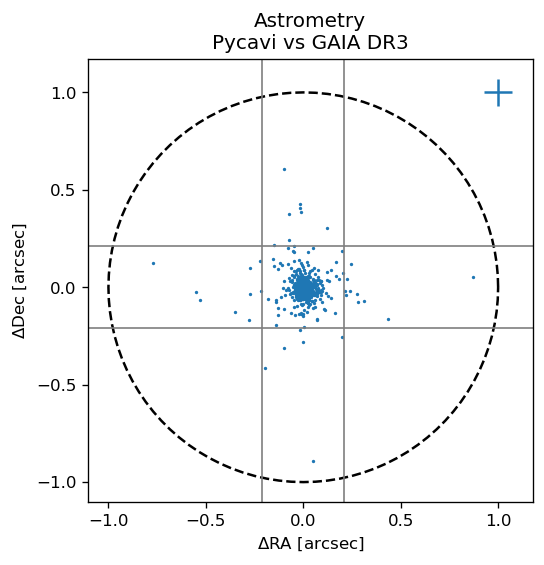

In [45]:
import matplotlib.pyplot as plt

ra_py = mergedtable['raj2000']
ra_gaia = mergedtable['raj2000_gaia']
de_py = mergedtable['dej2000']
de_gaia = mergedtable['dej2000_gaia']

ra_gaia_err = mergedtable['raj2000_error_gaia']
de_gaia_err = mergedtable['dej2000_error_gaia']

ra_gaia_err_mean = np.nanmean(ra_gaia_err)
de_gaia_err_mean = np.nanmean(de_gaia_err)

mean_de = np.nanmean(de_py)
t = np.linspace(0, 2*np.pi, 101)
x = np.cos(t)
y = np.sin(t)

fig, ax = plt.subplots(dpi=120)
ax.scatter(3600*(ra_py-ra_gaia), 3600*np.cos(mean_de*np.pi/180)*(de_py-de_gaia), s=1)
ax.plot(x, y, ls='--', color='black')
ax.axvline(-0.21, lw=1, color='tab:gray')
ax.axvline(0.21, lw=1, color='tab:gray')
ax.axhline(-0.21, lw=1, color='tab:gray')
ax.axhline(0.21, lw=1, color='tab:gray')

ax.errorbar(1,1,xerr=ra_gaia_err_mean, yerr=de_gaia_err_mean)
ax.set_xlabel(r'$\Delta$RA [arcsec]')
ax.set_ylabel(r'$\Delta$Dec [arcsec]')
ax.set_title('Astrometry\nPycavi vs GAIA DR3')
ax.set_aspect(1)

plt.show()

### Magnitudes check

The magnitudes does not show any unexpected feature. The slope of r_SDSS vs NB_659 magnitudes is slightly greater than 1. The stars that show separations larger than 1 arcsec does not show any remarkable position in the mag vs mag diagram<br>

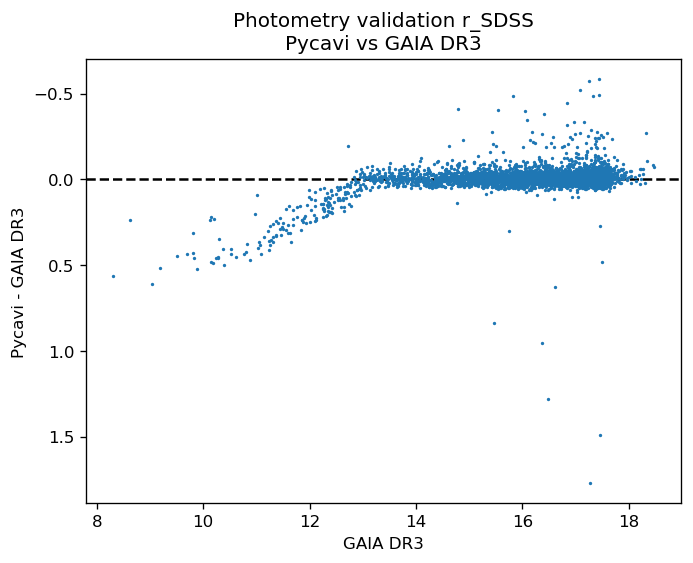

In [24]:
mag_r = mergedtable['MAG_PETRO_r_SDSS']
mag_r_gaia = mergedtable['r_sdss_mag_gaia']

fig, ax = plt.subplots(dpi=120)
ax.scatter(mag_r_gaia, mag_r - mag_r_gaia, s=1)
ax.axhline(0, ls='--', color='black', zorder=-1)
ax.invert_yaxis()
ax.set_xlabel('GAIA DR3')
ax.set_ylabel('Pycavi - GAIA DR3')
ax.set_title('Photometry validation r_SDSS\nPycavi vs GAIA DR3')
plt.show()

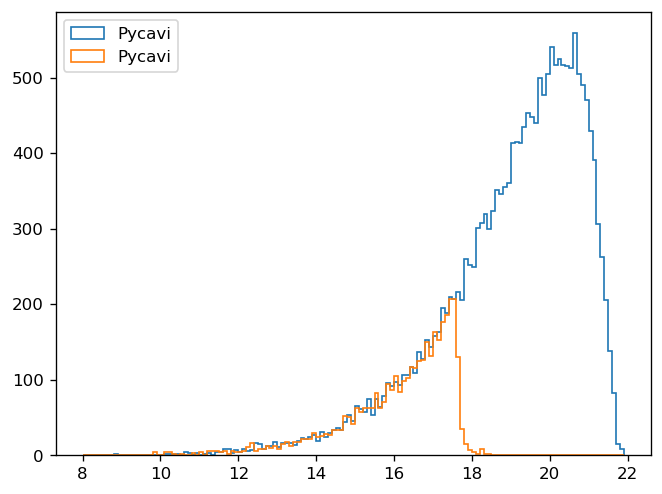

In [25]:
fig, ax = plt.subplots(dpi=120)
bins = np.arange(8, 22, 0.1)
ax.hist(mag_r, bins=bins, histtype='step', label='Pycavi')
ax.hist(mag_r_gaia, bins=bins, histtype='step', label='Pycavi')
ax.legend(loc='upper left')
plt.show()

### ellipticity

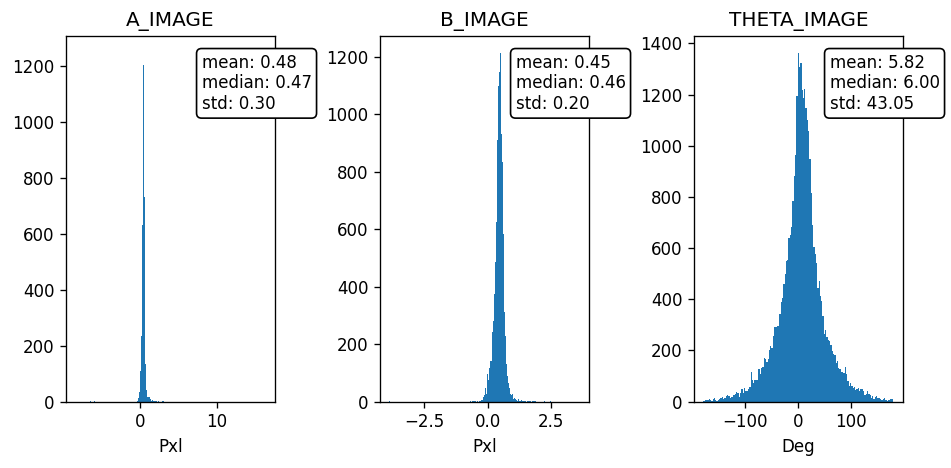

In [38]:
a_r = mergedtable['A_IMAGE_r_SDSS']
a_nb = mergedtable['A_IMAGE_NB_659']
b_r = mergedtable['B_IMAGE_r_SDSS']
b_nb = mergedtable['B_IMAGE_NB_659']
theta_r = mergedtable['THETA_IMAGE_r_SDSS']
theta_nb = mergedtable['THETA_IMAGE_NB_659']

median_dif_a = np.nanmedian(a_r-a_nb)
mean_dif_a = np.nanmean(a_r-a_nb)
std_dif_a = np.nanstd(a_r-a_nb)

median_dif_b = np.nanmedian(b_r-b_nb)
mean_dif_b = np.nanmean(b_r-b_nb)
std_dif_b = np.nanstd(b_r-b_nb)

median_dif_theta = np.nanmedian(theta_r-theta_nb)
mean_dif_theta = np.nanmean(theta_r-theta_nb)
std_dif_theta = np.nanstd(theta_r-theta_nb)

fig, ax = plt.subplots(ncols=3, figsize=(8,4), dpi=120)
ax[0].hist(a_r - a_nb, bins='fd')
ax[1].hist(b_r - b_nb, bins='fd')
ax[2].hist(theta_r - theta_nb, bins='fd')

ax[0].text(x=0.65, y=0.8, 
           s='mean: {:.2f}\nmedian: {:.2f}\nstd: {:.2f}'.format(mean_dif_a, median_dif_a, std_dif_a), 
           transform=ax[0].transAxes, bbox=dict(boxstyle='round', facecolor='white'))

ax[1].text(x=0.65, y=0.8, 
           s='mean: {:.2f}\nmedian: {:.2f}\nstd: {:.2f}'.format(mean_dif_b, median_dif_b, std_dif_b), 
           transform=ax[1].transAxes, bbox=dict(boxstyle='round', facecolor='white'))

ax[2].text(x=0.65, y=0.8, 
           s='mean: {:.2f}\nmedian: {:.2f}\nstd: {:.2f}'.format(mean_dif_theta, median_dif_theta, std_dif_theta), 
           transform=ax[2].transAxes, bbox=dict(boxstyle='round', facecolor='white'))

ax[0].set_title('A_IMAGE')
ax[1].set_title('B_IMAGE')
ax[2].set_title('THETA_IMAGE')

ax[0].set_xlabel('Pxl')
ax[1].set_xlabel('Pxl')
ax[2].set_xlabel('Deg')
plt.tight_layout()
plt.show()

### Clean and check of the merged catalogue

For the clean, remove all sources that are not detected in both catalogues.<br>
Pros: easier comparison with Gaia crossmatching.<br>
Cons: We lose some stars in the edge of the images.<br>

Combine the ra/dec, and reject sources with a difference larger than 1 arcsec from one another.<br>
Keep the rest of tags differentiated with the filter tag. One may be interested in study the differences between filters. <br>

In [48]:
basedir = '/home/lientur/Investigacion/OmegaCam/Work_dir/science/BD_Pav/Calibration_dir/'
cleantable = load_catalogue(basedir + 'BD_Pav_merged_catalogue.fits', extnumber=1)
print(cleantable.colnames)

['NUMBER_r_SDSS', 'EXT_NUMBER_r_SDSS', 'FLUX_ISO_r_SDSS', 'FLUXERR_ISO_r_SDSS', 'MAG_ISO_r_SDSS', 'MAGERR_ISO_r_SDSS', 'FLUX_AUTO_r_SDSS', 'FLUXERR_AUTO_r_SDSS', 'MAG_AUTO_r_SDSS', 'MAGERR_AUTO_r_SDSS', 'FLUX_PETRO_r_SDSS', 'FLUXERR_PETRO_r_SDSS', 'MAG_PETRO_r_SDSS', 'MAGERR_PETRO_r_SDSS', 'X_IMAGE_r_SDSS', 'Y_IMAGE_r_SDSS', 'A_IMAGE_r_SDSS', 'B_IMAGE_r_SDSS', 'THETA_IMAGE_r_SDSS', 'XWIN_IMAGE_r_SDSS', 'YWIN_IMAGE_r_SDSS', 'ERRX2WIN_IMAGE_r_SDSS', 'ERRY2WIN_IMAGE_r_SDSS', 'ERRXYWIN_IMAGE_r_SDSS', 'ERRX2WIN_WORLD_r_SDSS', 'ERRY2WIN_WORLD_r_SDSS', 'ERRXYWIN_WORLD_r_SDSS', 'ERRAWIN_IMAGE_r_SDSS', 'ERRBWIN_IMAGE_r_SDSS', 'ERRTHETAWIN_IMAGE_r_SDSS', 'FLAGS_r_SDSS', 'FLAGS_WEIGHT_r_SDSS', 'FLAGS_WIN_r_SDSS', 'FWHM_IMAGE_r_SDSS', 'ELONGATION_r_SDSS', 'ELLIPTICITY_r_SDSS', 'CLASS_STAR_r_SDSS', 'NUMBER_NB_659', 'EXT_NUMBER_NB_659', 'FLUX_ISO_NB_659', 'FLUXERR_ISO_NB_659', 'MAG_ISO_NB_659', 'MAGERR_ISO_NB_659', 'FLUX_AUTO_NB_659', 'FLUXERR_AUTO_NB_659', 'MAG_AUTO_NB_659', 'MAGERR_AUTO_NB_659', '

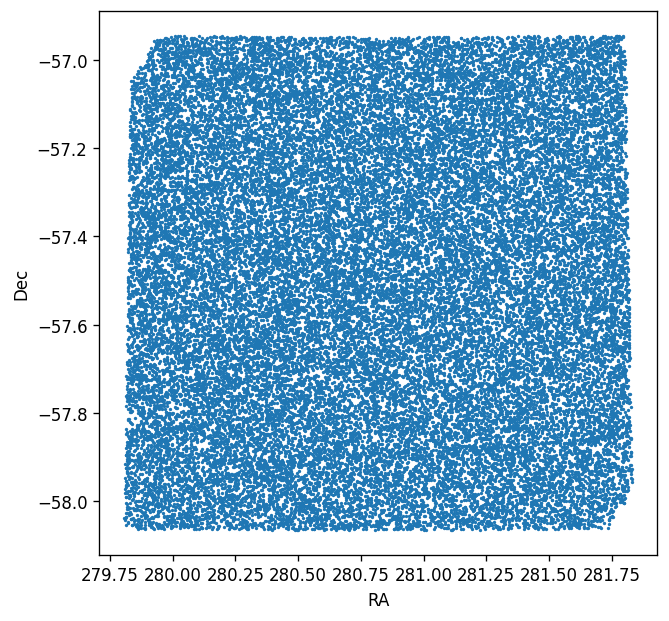

In [49]:
ra = cleantable['raj2000']
de = cleantable['dej2000']

fig, ax = plt.subplots(figsize=(6,6), dpi=120)
ax.scatter(ra, de, s=1)
ax.set_xlabel('RA')
ax.set_ylabel('Dec')
plt.show()

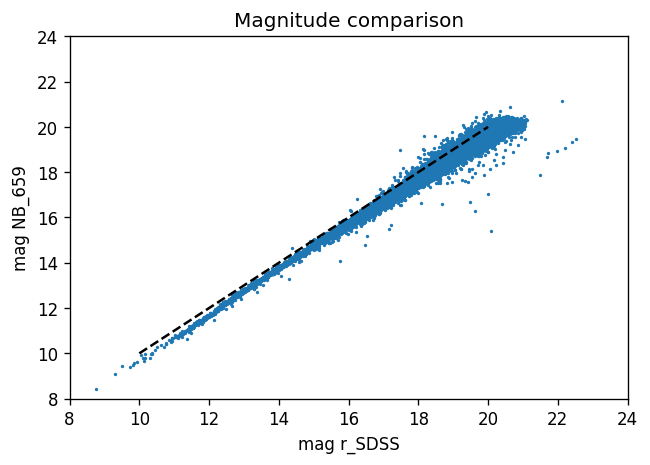

In [51]:
mag_r = cleantable['MAG_PETRO_r_SDSS']
mag_nb = cleantable['MAG_PETRO_NB_659']

fig, ax = plt.subplots(dpi=120)
ax.scatter(mag_r, mag_nb, s=1)
ax.plot([10,20],[10,20], ls='--', color='black')
ax.set_ylim(8,24)
ax.set_xlim(8,24)
ax.set_xlabel('mag r_SDSS')
ax.set_ylabel('mag NB_659')
ax.set_title('Magnitude comparison')
plt.show()

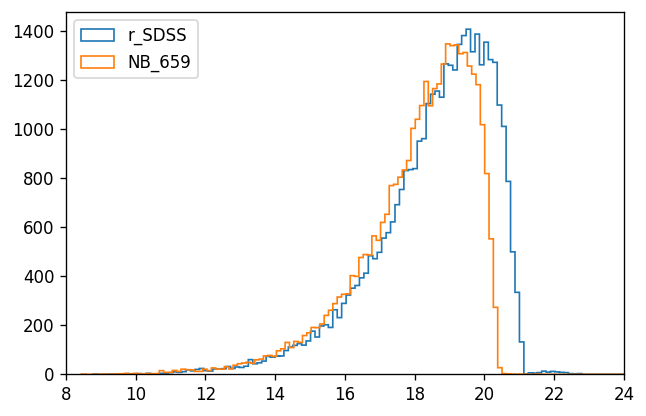

In [53]:
fig, ax = plt.subplots(dpi=120)

ax.hist(mag_r, bins='fd', label='r_SDSS', histtype='step')
ax.hist(mag_nb, bins='fd', label='NB_659', histtype='step')
ax.set_xlim(8,24)
ax.legend(loc='upper left')
plt.show()

### Combine the clean catalogue with Gaia

In [5]:
basedir = '/home/lientur/Investigacion/OmegaCam/Work_dir/science/BD_Pav/Calibration_dir/'
merged_clean_gaia = load_catalogue(basedir + 'BD_Pav_merged_catalogue.fits', extnumber=1)

### r_SDSS vs GAIA check

ZP:
PETRO: -0.01 mag
AUTO: -0.04 mag
ISO: -0.03 mag


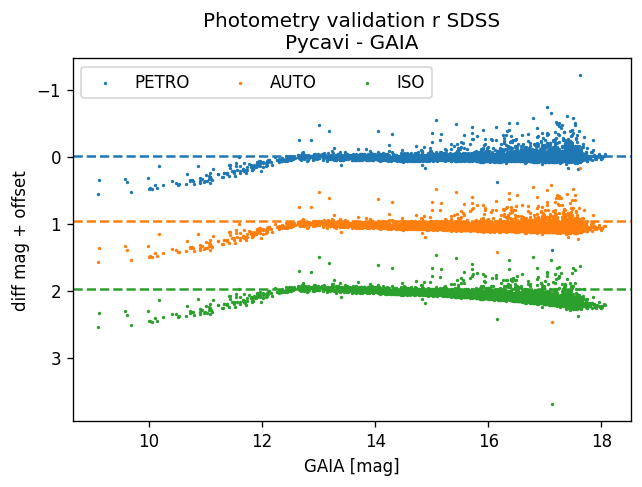

In [18]:
import matplotlib.pyplot as plt

def getzp(mag, mag_ref):
    sel = (mag_ref > 13) & (mag_ref < 16)
    return np.nanmedian(mag_ref[sel] - mag[sel])
    

mag_1_petro = merged_clean_gaia['MAG_PETRO_r_SDSS']
mag_1_auto = merged_clean_gaia['MAG_AUTO_r_SDSS']
mag_1_iso = merged_clean_gaia['MAG_ISO_r_SDSS']
mag_2 = merged_clean_gaia['r_SDSS_gaia']

zp_petro = getzp(mag_1_petro, mag_2)
zp_auto = getzp(mag_1_auto, mag_2)
zp_iso = getzp(mag_1_iso, mag_2)

print('ZP:')
print('PETRO: {:.2f} mag'.format(zp_petro))
print('AUTO: {:.2f} mag'.format(zp_auto))
print('ISO: {:.2f} mag'.format(zp_iso))

fig, ax = plt.subplots(dpi=120)
ax.scatter(mag_2, mag_1_petro-mag_2, s=1, label='PETRO')
ax.scatter(mag_2, 1+mag_1_auto-mag_2, s=1, label='AUTO')
ax.scatter(mag_2, 2+mag_1_iso-mag_2, s=1, label='ISO')
ax.axhline(zp_petro, ls='--', color='tab:blue')
ax.axhline(zp_auto+1, ls='--', color='tab:orange')
ax.axhline(zp_iso+2, ls='--', color='tab:green')
ax.invert_yaxis()

ax.legend(loc=0, ncols=3)
ax.set_xlabel('GAIA [mag]')
ax.set_ylabel('diff mag + offset')
ax.set_title('Photometry validation r SDSS\nPycavi - GAIA')

plt.savefig(basedir+'photometry_validation_GAIA.png', format='png', facecolor='white')
plt.show()

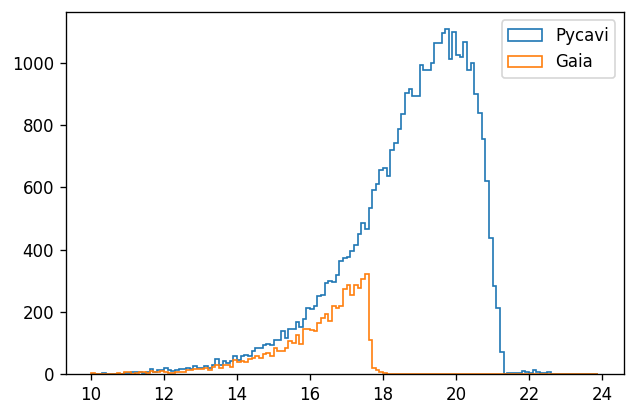

In [112]:
fig, ax = plt.subplots(dpi=120)
bins = np.arange(10, 24, 0.1)
ax.hist(mag_1_petro[mag_1_petro < 99], bins=bins, histtype='step', label='Pycavi')
ax.hist(mag_2, bins=bins, histtype='step', label='Gaia')
ax.legend(loc=0)
plt.show()

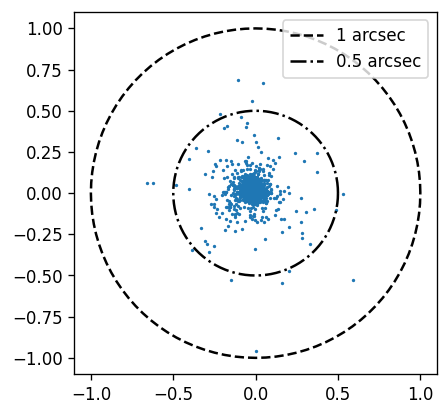

In [21]:
ra1 = merged_clean_gaia['raj2000']
ra2 = merged_clean_gaia['raj2000_gaia']
de1 = merged_clean_gaia['dej2000']
de2 = merged_clean_gaia['dej2000_gaia']

t = np.linspace(0, 2*np.pi, 101)
x = np.cos(t)
y = np.sin(t)

fig, ax = plt.subplots(dpi=120)
ax.scatter(3600*(ra1-ra2)*np.cos(np.nanmean(de1)), 3600*(de1-de2), s=1)
ax.plot(x, y, ls='--', color='black', label='1 arcsec')
ax.plot(0.5*x, 0.5*y, ls='-.', color='black', label='0.5 arcsec')
ax.set_aspect(1)
ax.legend(loc=0)

plt.show()

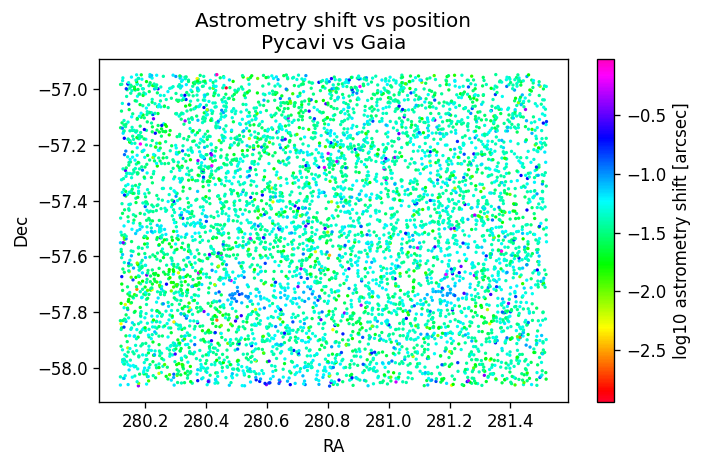

In [22]:
r = np.log10(3600*(((ra1-ra2)*np.cos(np.nanmean(de1)))**2 + (de1-de2)**2)**(1/2))

fig, ax = plt.subplots(dpi=120)
im = ax.scatter(ra1, de1, c=r, s=1, cmap='gist_rainbow')
fig.colorbar(im, ax=ax, label='log10 astrometry shift [arcsec]')
ax.set_title('Astrometry shift vs position\nPycavi vs Gaia')
ax.set_ylabel('Dec')
ax.set_xlabel('RA')
plt.tight_layout()
plt.savefig(basedir+'astrometry_validation_GAIA.png', format='png', facecolor='white')
plt.show()

### Validation against SkyMapper

In [11]:
target_name='/home/lientur/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav'

In [12]:
import urllib.request

sm_query_name = target_name+'_sm_query.csv'
py_merged_name = target_name + '_merged_catalogue.fits'

if not os.path.isfile(sm_query_name):
    
    headers_image = fits.getheader(images_to_check[i])
    sm_query = "http://skymapper.anu.edu.au/sm-cone/public/query?RA={}&DEC={}&SR={}&VERB=3&RESPONSEFORMAT=CSV".format(headers_image['RA'], headers_image['DEC'], 1.0)
    print(sm_query)

    with urllib.request.urlopen(sm_query) as f:
        charset = f.headers.get_content_charset()
        line_list = f.read().decode(charset).split('\r\n')

    # and here we write to file
    with open(sm_query_name, "w") as f:
        for aline in line_list:
            print(aline, file=f)
            
skymapper_table = pd.read_csv(sm_query_name)
skymapper_table = Table.from_pandas(skymapper_table)

for col in skymapper_table.colnames:
    skymapper_table.rename_column(col, col+'_sm')
    
py_merged_table = load_catalogue(py_merged_name, extnumber=1)

py_sm_matched_table = crossmatch_catalogues(py_merged_table, skymapper_table, 
                                            radec_tag_1=['raj2000', 'dej2000'], 
                                            radec_tag_2=['raj2000_sm', 'dej2000_sm'])

py_sm_matched_table.write(target_name+'_merged_catalogue_skymaper.fits', format='fits', overwrite=True)

In [93]:
print(skymapper_table.colnames)

['r_cntr_sm', 'object_id_sm', 'raj2000_sm', 'dej2000_sm', 'e_raj2000_sm', 'e_dej2000_sm', 'smss_j_sm', 'mean_epoch_sm', 'rms_epoch_sm', 'glon_sm', 'glat_sm', 'flags_sm', 'nimaflags_sm', 'ngood_sm', 'u_flags_sm', 'u_nimaflags_sm', 'u_ngood_sm', 'u_nclip_sm', 'v_flags_sm', 'v_nimaflags_sm', 'v_ngood_sm', 'v_nclip_sm', 'g_flags_sm', 'g_nimaflags_sm', 'g_ngood_sm', 'g_nclip_sm', 'r_flags_sm', 'r_nimaflags_sm', 'r_ngood_sm', 'r_nclip_sm', 'i_flags_sm', 'i_nimaflags_sm', 'i_ngood_sm', 'i_nclip_sm', 'z_flags_sm', 'z_nimaflags_sm', 'z_ngood_sm', 'z_nclip_sm', 'class_star_sm', 'chi2_psf_sm', 'flags_psf_sm', 'radius_petro_sm', 'mean_fwhm_sm', 'u_psf_sm', 'e_u_psf_sm', 'u_petro_sm', 'e_u_petro_sm', 'u_apc05_sm', 'e_u_apc05_sm', 'u_mmvar_sm', 'v_psf_sm', 'e_v_psf_sm', 'v_petro_sm', 'e_v_petro_sm', 'v_apc05_sm', 'e_v_apc05_sm', 'v_mmvar_sm', 'g_psf_sm', 'e_g_psf_sm', 'g_petro_sm', 'e_g_petro_sm', 'g_apc05_sm', 'e_g_apc05_sm', 'g_mmvar_sm', 'r_psf_sm', 'e_r_psf_sm', 'r_petro_sm', 'e_r_petro_sm', 'r_

In [95]:
print(py_sm_matched_table.colnames)

['r_cntr_sm', 'object_id_sm', 'raj2000_sm', 'dej2000_sm', 'e_raj2000_sm', 'e_dej2000_sm', 'smss_j_sm', 'mean_epoch_sm', 'rms_epoch_sm', 'glon_sm', 'glat_sm', 'flags_sm', 'nimaflags_sm', 'ngood_sm', 'u_flags_sm', 'u_nimaflags_sm', 'u_ngood_sm', 'u_nclip_sm', 'v_flags_sm', 'v_nimaflags_sm', 'v_ngood_sm', 'v_nclip_sm', 'g_flags_sm', 'g_nimaflags_sm', 'g_ngood_sm', 'g_nclip_sm', 'r_flags_sm', 'r_nimaflags_sm', 'r_ngood_sm', 'r_nclip_sm', 'i_flags_sm', 'i_nimaflags_sm', 'i_ngood_sm', 'i_nclip_sm', 'z_flags_sm', 'z_nimaflags_sm', 'z_ngood_sm', 'z_nclip_sm', 'class_star_sm', 'chi2_psf_sm', 'flags_psf_sm', 'radius_petro_sm', 'mean_fwhm_sm', 'u_psf_sm', 'e_u_psf_sm', 'u_petro_sm', 'e_u_petro_sm', 'u_apc05_sm', 'e_u_apc05_sm', 'u_mmvar_sm', 'v_psf_sm', 'e_v_psf_sm', 'v_petro_sm', 'e_v_petro_sm', 'v_apc05_sm', 'e_v_apc05_sm', 'v_mmvar_sm', 'g_psf_sm', 'e_g_psf_sm', 'g_petro_sm', 'e_g_petro_sm', 'g_apc05_sm', 'e_g_apc05_sm', 'g_mmvar_sm', 'r_psf_sm', 'e_r_psf_sm', 'r_petro_sm', 'e_r_petro_sm', 'r_

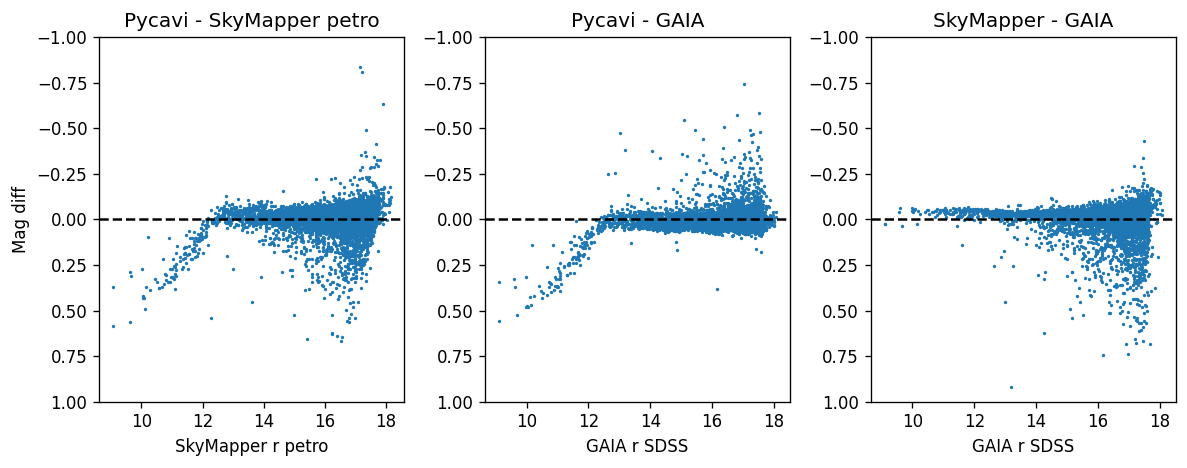

In [20]:
def getzp(mag, mag_ref):
    sel = (mag_ref > 13) & (mag_ref < 16)
    return np.nanmedian(mag_ref[sel] - mag[sel])

r_py_petro = py_sm_matched_table['MAG_PETRO_r_SDSS']
r_sm_petro = py_sm_matched_table['r_petro_sm']
r_gaia = py_sm_matched_table['r_SDSS_gaia']

sel = (r_py_petro < 25) & (r_sm_petro < 25) & (r_gaia < 25)

fig, ax = plt.subplots(ncols=3, figsize=(10,4), dpi=120)

ax[0].scatter(r_sm_petro[sel], r_py_petro[sel]-r_sm_petro[sel], s=1)
ax[0].set_xlabel('SkyMapper r petro')
ax[0].set_ylabel('Mag diff')
ax[0].set_title('Pycavi - SkyMapper petro')
ax[0].axhline(0.0, ls='--', color='black')
ax[0].set_ylim(-1,1)
ax[0].invert_yaxis()

ax[1].scatter(r_gaia[sel], r_py_petro[sel]-r_gaia[sel], s=1)
ax[1].set_xlabel('GAIA r SDSS')
ax[1].set_title('Pycavi - GAIA')
ax[1].axhline(0.0, ls='--', color='black')
ax[1].set_ylim(-1,1)
ax[1].invert_yaxis()

ax[2].scatter(r_gaia[sel], r_gaia[sel]-r_sm_petro[sel], s=1)
ax[2].set_xlabel('GAIA r SDSS')
ax[2].set_title('SkyMapper - GAIA')
ax[2].axhline(0.0, ls='--', color='black')
ax[2].set_ylim(-1,1)
ax[2].invert_yaxis()

plt.tight_layout()
plt.savefig(basedir+'photometry_validation_skymapper.png', format='png', facecolor='white')
plt.show()

## Comparison with VPHAS+

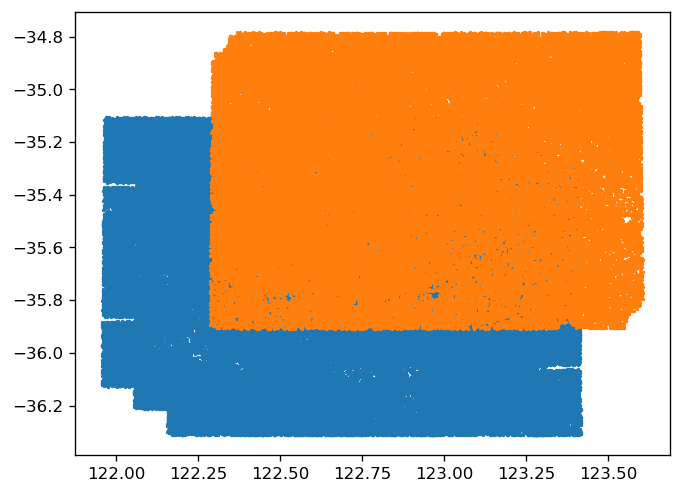

In [64]:
vphas_cat = load_catalogue('/home/lceledon/Investigacion/OmegaCam/Vphas_data/CP_Pup/ADP.2017-11-03T09:28:40.092.fits', extnumber=1)
pycavi_cat = load_catalogue('/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_merged_catalogue_illumination_correction_kriggin.fits', extnumber=1)

fig, ax = plt.subplots(dpi=120)
ax.scatter(vphas_cat['RA2000'], vphas_cat['DEC2000'], s=1, color='tab:blue')
ax.scatter(pycavi_cat['raj2000'], pycavi_cat['dej2000'], s=1, color='tab:orange')
plt.show()

for col in vphas_cat.colnames:
    vphas_cat.rename_column(col, col+'_vphas')

py_vphas_matched_table = crossmatch_catalogues(pycavi_cat, vphas_cat, 
                                               radec_tag_1=['raj2000', 'dej2000'], 
                                               radec_tag_2=['RA2000_vphas', 'DEC2000_vphas'])

In [13]:
print(py_vphas_matched_table.colnames)

['IAUNAME_vphas', 'SOURCEID_vphas', 'RA2000_vphas', 'DEC2000_vphas', 'L_vphas', 'B_vphas', 'MERGEDCLASS_vphas', 'UMGPNT_vphas', 'UMGPNTERR_vphas', 'GMR2PNT_vphas', 'GMR2PNTERR_vphas', 'RMHAVPHASPNT_vphas', 'RMHAVPHASPNTERR_vphas', 'RMIPNT_vphas', 'RMIPNTERR_vphas', 'UMJD_vphas', 'UAPERMAG3_vphas', 'UAPERMAG3ERR_vphas', 'UAPERMAG4_vphas', 'UAPERMAG4ERR_vphas', 'UAPERMAG6_vphas', 'UAPERMAG6ERR_vphas', 'UGAUSIG_vphas', 'UELL_vphas', 'UPA_vphas', 'UERRBITS_vphas', 'UPPERRBITS_vphas', 'UAVERAGECONF_vphas', 'UCLASS_vphas', 'UXI_vphas', 'UETA_vphas', 'USEQNUM_vphas', 'GMJD_vphas', 'GAPERMAG3_vphas', 'GAPERMAG3ERR_vphas', 'GAPERMAG4_vphas', 'GAPERMAG4ERR_vphas', 'GAPERMAG6_vphas', 'GAPERMAG6ERR_vphas', 'GGAUSIG_vphas', 'GELL_vphas', 'GPA_vphas', 'GERRBITS_vphas', 'GPPERRBITS_vphas', 'GAVERAGECONF_vphas', 'GCLASS_vphas', 'GXI_vphas', 'GETA_vphas', 'GSEQNUM_vphas', 'R2MJD_vphas', 'R2APERMAG3_vphas', 'R2APERMAG3ERR_vphas', 'R2APERMAG4_vphas', 'R2APERMAG4ERR_vphas', 'R2APERMAG6_vphas', 'R2APERMAG6

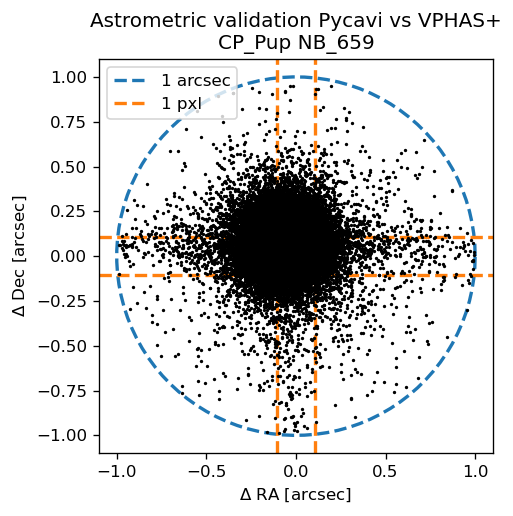

In [65]:
# Astrometric validation
ra_py = py_vphas_matched_table['raj2000']
de_py = py_vphas_matched_table['dej2000']
ra_vphas = py_vphas_matched_table['RA2000_vphas']
de_vphas = py_vphas_matched_table['DEC2000_vphas']

mean_de = np.nanmean(de_py) * np.pi/180
delta_ra = np.cos(mean_de) * (ra_py - ra_vphas) * 3600
delta_de = (de_py - de_vphas) * 3600

t = np.linspace(0, 2*np.pi, 100)
x = np.cos(t)
y = np.sin(t)

fig, ax = plt.subplots(figsize=(7, 4.4), dpi=120)
ax.scatter(delta_ra, delta_de, s=1, color='black')
ax.plot(x, y, ls='--', color='tab:blue', label='1 arcsec', lw=2, zorder=-1)
ax.axhline(-0.21/2, ls='--', lw=2, color='tab:orange', label='1 pxl', zorder=-1)
ax.axhline(0.21/2, ls='--', lw=2, color='tab:orange', zorder=-1)
ax.axvline(-0.21/2, ls='--', lw=2, color='tab:orange', zorder=-1)
ax.axvline(0.21/2, ls='--', lw=2, color='tab:orange', zorder=-1)
ax.legend(loc='upper left')
ax.set_aspect(1)
ax.set_xlabel(r'$\Delta$ RA [arcsec]')
ax.set_ylabel(r'$\Delta$ Dec [arcsec]')
ax.set_title('Astrometric validation Pycavi vs VPHAS+\nCP_Pup NB_659')
plt.tight_layout()
plt.savefig('/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_astrometric_validation_VPHAS+.png', 
            format='png', facecolor='white')
plt.show()

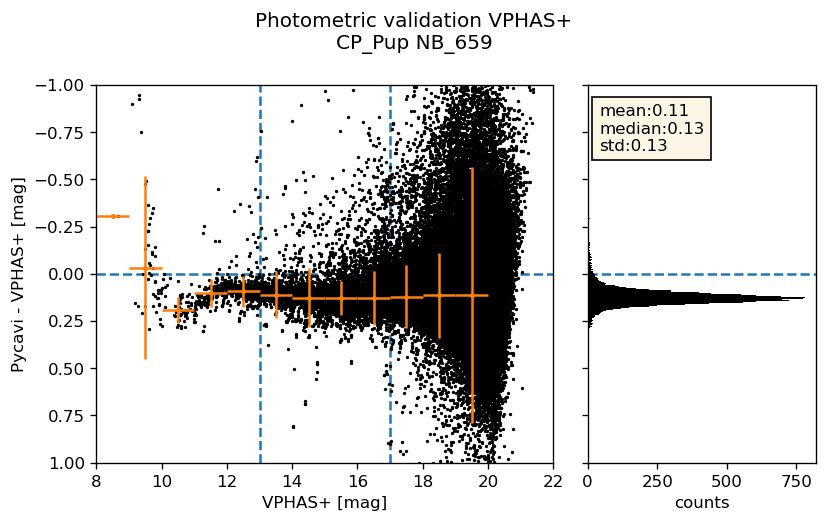

In [66]:
mag_py = py_vphas_matched_table['mag_petro_nb_659']
mag_err_py = py_vphas_matched_table['magerr_petro_nb_659']
mag_vphas = py_vphas_matched_table['HAVPHASAPERMAG4_vphas']
mag_err_vphas = py_vphas_matched_table['HAVPHASAPERMAG6ERR_vphas']
magmin = 13
magmax = 17

sel_mag = (mag_vphas >= magmin) & (mag_vphas <= magmax)
sel_mag_err = (mag_err_vphas / mag_vphas < 0.1)
sel = sel_mag & sel_mag_err 

mean_dif = np.nanmean(mag_py[sel]-mag_vphas[sel])
median_dif = np.nanmedian(mag_py[sel]-mag_vphas[sel])
std_dif = np.nanstd(mag_py[sel]-mag_vphas[sel])
stats_text = 'mean:{:.2f}\nmedian:{:.2f}\nstd:{:.2f}'.format(mean_dif, median_dif, std_dif)

bins = np.arange(8, 21, 1)

fig, ax = plt.subplots(ncols=2, width_ratios=(2,1), figsize=(7, 4.4), dpi=120)
ax[0].scatter(mag_vphas[sel_mag_err], mag_py[sel_mag_err]-mag_vphas[sel_mag_err], s=1, color='black')

for i in range(len(bins)-1):
    sel_bin = (mag_vphas > bins[i]) & (mag_vphas < bins[i+1])
    median_bin = np.nanmedian(mag_py[sel_bin]-mag_vphas[sel_bin])
    std_bin = np.nanstd(mag_py[sel_bin]-mag_vphas[sel_bin])
    ax[0].errorbar(x=0.5*(bins[i]+bins[i+1]), y=median_bin, yerr=std_bin, xerr=0.5, marker='o', color='tab:orange', ms=2)

ax[0].axhline(0, ls='--', color='tab:blue', zorder=-1)
ax[0].axvline(magmin, ls='--', color='tab:blue', zorder=-1)
ax[0].axvline(magmax, ls='--', color='tab:blue', zorder=-1)
ax[0].set_ylim(-1,1)
ax[0].set_xlim(8, 22)
ax[0].invert_yaxis()
ax[0].set_xlabel('VPHAS+ [mag]')
ax[0].set_ylabel('Pycavi - VPHAS+ [mag]')

ax[1].hist(mag_py[sel]-mag_vphas[sel], bins='fd', orientation='horizontal', color='black')
ax[1].axhline(0, ls='--', color='tab:blue', zorder=-1)
ax[1].text(x=0.05, y=0.95, s=stats_text, transform=ax[1].transAxes, bbox=dict(facecolor='oldlace'), va='top', ha='left')
ax[1].set_ylim(-1,1)
ax[1].invert_yaxis()
ax[1].yaxis.set_ticklabels([])
ax[1].set_xlabel('counts')

fig.suptitle('Photometric validation VPHAS+\nCP_Pup NB_659')
plt.tight_layout()
plt.savefig('/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_photometric_validation_VPHAS+.png', 
            format='png', facecolor='white')
plt.show()

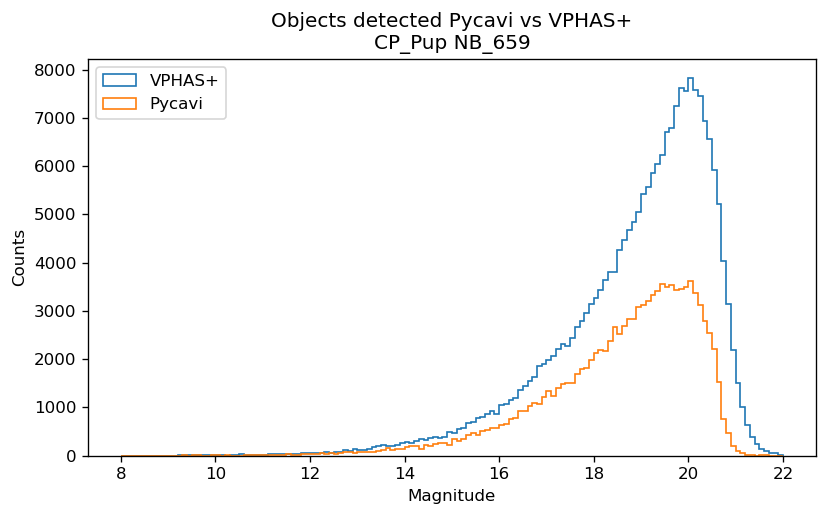

In [67]:
fig, ax = plt.subplots(figsize=(7, 4.4), dpi=120)
ax.hist(mag_vphas, bins=np.arange(8, 22.1, 0.1), histtype='step', label='VPHAS+')
ax.hist(mag_py, bins=np.arange(8, 22.1, 0.1), histtype='step', label='Pycavi')
ax.legend(loc='upper left')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Counts')
ax.set_title('Objects detected Pycavi vs VPHAS+\nCP_Pup NB_659')
plt.tight_layout()
plt.savefig('/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_objects_detected_VPHAS+.png', 
            format='png', facecolor='white')
plt.show()

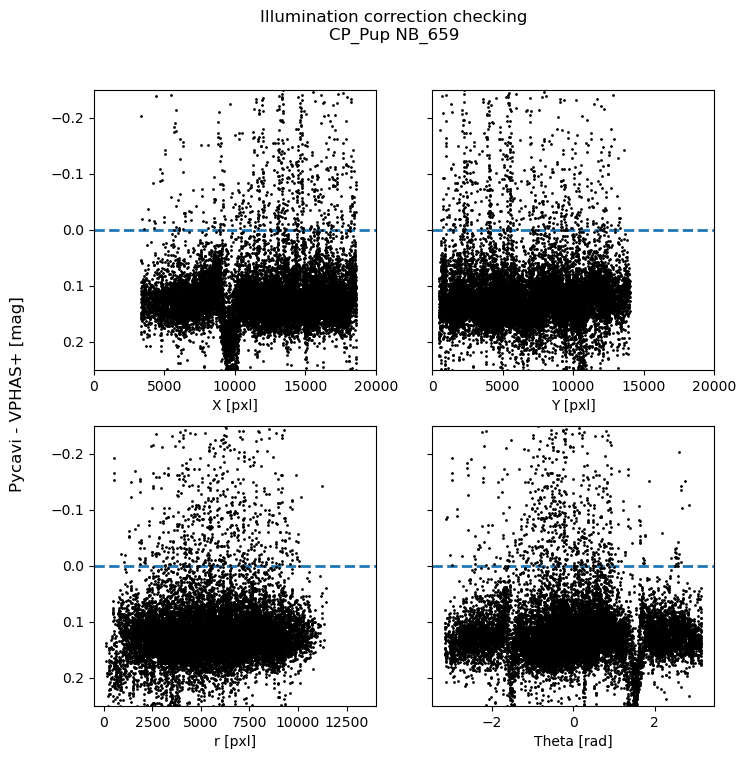

In [73]:
# Illumination correction cheking
x_pxl = py_vphas_matched_table['x_image_nb_659']
y_pxl = py_vphas_matched_table['y_image_nb_659']
center_x = np.nanmax(x_pxl)/2
center_y = np.nanmax(y_pxl)/2
r_pxl = np.sqrt((x_pxl-center_x)**2 + (y_pxl-center_y)**2)
theta_pxl = np.arctan2(y_pxl-center_y, x_pxl-center_x)

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(8, 8))
ax[0,0].scatter(x_pxl[sel], mag_py[sel]-mag_vphas[sel], s=1, color='black')
ax[0,0].set_xlabel('X [pxl]')
ax[0,0].set_xlim(0,20000)

ax[0,1].scatter(y_pxl[sel], mag_py[sel]-mag_vphas[sel], s=1, color='black')
ax[0,1].set_xlabel('Y [pxl]')
ax[0,1].set_xlim(0,20000)
ax[0,1].yaxis.set_ticklabels([])

ax[1,0].scatter(r_pxl[sel], mag_py[sel]-mag_vphas[sel], s=1, color='black')
ax[1,0].set_xlabel('r [pxl]')
ax[1,0].set_xlim(-500, 14000)

ax[1,1].scatter(theta_pxl[sel], mag_py[sel]-mag_vphas[sel], s=1, color='black')
ax[1,1].set_xlabel('Theta [rad]')
ax[1,1].yaxis.set_ticklabels([])

for axi in ax.flatten():
    axi.axhline(0, ls='--', lw=2, color='tab:blue', zorder=-1)
    axi.set_ylim(-0.25,0.25)
    axi.invert_yaxis()

fig.supylabel('Pycavi - VPHAS+ [mag]')
fig.suptitle('Illumination correction checking\nCP_Pup NB_659')
plt.savefig('/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_illumination_correction_checking_VPHAS+.png', 
            format='png', facecolor='white')
plt.show()    

## Applying the illumination correction

The illumination correction was succesfully applied to the catalogues, but the comparison with the Gaia photometry shows an ofset of ~0.05 magnitudes in ZP.

What I need to do now...
* Comparison with SkyMapper and VPHAS+ when possible
* Create some functions that do this



In [2]:
import numpy as np
from scipy.interpolate import RegularGridInterpolator

from astropy.io import fits
from astropy.table import Table

def load_catalogue(catalogue_path, extnumber=2, colname=None):
    # the extension name varies with the catalogue. For the sextractor output, the extnumber is two
    hdul = fits.open(catalogue_path)
    table_data = hdul[extnumber].data
    hdul.close()
    output_table = Table(table_data)

    if colname is None:
        return output_table
    else:
        return output_table[colname]

def applykrigginilluminationcorrection(kriggin_fits_path, catalogue_path):
    """
    Apply the illumination correction from Krigging method to the catalogue.
    It read the kriggin resulting fits file, determine the band, and apply the correction to the pycavi magnitudes in the catalogue.

    Parameters:
        kriggin_fits_path:str
            The path to the krigging fits file with the illumination correction
        catalogue_path:str
            The path to the catalogue which will be corrected by illumination
    """
    kriggin_fits_data = fits.getdata(kriggin_fits_path)
    kriggin_fits_header = fits.getheader(kriggin_fits_path)
    
    n, m = np.shape(kriggin_fits_data)
    x_kriggin = 1.0*np.arange(m) / m
    y_kriggin = 1.0*np.arange(n) / n  # kriggin data between 0 and 1

    band = kriggin_fits_header['BAND'].lower()
    x_image = kriggin_fits_header['ORIG_W']
    y_image = kriggin_fits_header['ORIG_H']  # band, x, and y dimensiones of the image from the krigging headers
    
    catalogue = load_catalogue(catalogue_path, extnumber=1)
    
    mags_to_correct = []
    for col in catalogue.colnames:
        if 'mag_' in col and band in col:
            mags_to_correct.append(col)
    x_catalogue = catalogue['x_image_'+band] / x_image
    y_catalogue = catalogue['y_image_'+band] / y_image  # x/y position of the sources in the catalogue normalized from zero to one

    # here we do the interpolation of data
    # Use 'cubic' or 'quintic' for smoother interpolation  
    f = RegularGridInterpolator((x_kriggin, y_kriggin), kriggin_fits_data, method='cubic')  
    pts = np.vstack((y_catalogue, x_catalogue)).T

    mag_corr = f(pts)

    for col in mags_to_correct:
        catalogue[col] = catalogue[col] + mag_corr

    # save the catalogue as a new one
    savename = catalogue_path[:-5]+'_illumination_correction_kriggin.fits'.format(band)
    catalogue.write(savename, format='fits', overwrite=True)


In [70]:
import matplotlib.pyplot as plt

def createcataloguecheckplots(input_catalogue, band, magmin=13, magmax=17):
    """
    catalogue: the catalogue as astropy table or the path to the catalogue
    """
    if type(input_catalogue) is str:
        catalogue = load_catalogue(input_catalogue, extnumber=1)
    else:
        catalogue = input_catalogue.copy()

    # photometric checks, differences with the gaia reference catalogue
    mag_py = catalogue['mag_petro_'+band.lower()]
    mag_gaia = catalogue[band+'_gaia']

    sel = (mag_gaia >= magmin) & (mag_gaia <= magmax)
    mean_dif = np.nanmean(mag_py[sel]-mag_gaia[sel])
    median_dif = np.nanmedian(mag_py[sel]-mag_gaia[sel])
    std_dif = np.nanstd(mag_py[sel]-mag_gaia[sel])
    stats_text = 'mean:{:.2f}\nmedian:{:.2f}\nstd:{:.2f}'.format(mean_dif, median_dif, std_dif)

    bins = np.arange(8, 20, 1)
    
    # pycavi versus gaia
    fig, ax = plt.subplots(ncols=2, width_ratios=(2,1), figsize=(7, 4.4), dpi=120)
    ax[0].scatter(mag_gaia, mag_py-mag_gaia, s=1, color='black')

    for i in range(len(bins)-1):
        sel_bin = (mag_gaia > bins[i]) & (mag_gaia < bins[i+1])
        median_bin = np.nanmedian(mag_py[sel_bin]-mag_gaia[sel_bin])
        std_bin = np.nanstd(mag_py[sel_bin]-mag_gaia[sel_bin])
        ax[0].errorbar(x=0.5*(bins[i]+bins[i+1]), y=median_bin, yerr=std_bin, xerr=0.5, marker='o', color='tab:orange', ms=2)
    
    ax[0].axhline(0, ls='--', color='tab:blue', zorder=-1)
    ax[0].axvline(magmin, ls='--', color='tab:blue', zorder=-1)
    ax[0].axvline(magmax, ls='--', color='tab:blue', zorder=-1)
    ax[0].set_ylim(-1,1)
    ax[0].invert_yaxis()
    ax[0].set_xlabel('Gaia [mag]')
    ax[0].set_ylabel('Pycavi - Gaia [mag]')
    
    ax[1].hist(mag_py[sel]-mag_gaia[sel], bins='fd', orientation='horizontal', color='black')
    ax[1].axhline(0, ls='--', color='tab:blue', zorder=-1)
    ax[1].text(x=0.05, y=0.95, s=stats_text, transform=ax[1].transAxes, bbox=dict(facecolor='oldlace'), va='top', ha='left')
    ax[1].set_ylim(-1,1)
    ax[1].invert_yaxis()
    ax[1].yaxis.set_ticklabels([])
    ax[1].set_xlabel('counts')
    
    fig.suptitle('Photometric validation Gaia DR3\nCP Pup '+band)
    plt.tight_layout()
    plt.savefig('CP_Pup_photometric_validation_Gaia.png', format='png', facecolor='white')  # have to update the name depending on the frame 
    plt.show()

    # Histogram of magnitudes
    fig, ax = plt.subplots(figsize=(7, 4.4), dpi=120)
    ax.hist(mag_gaia, bins=np.arange(8, 22.1, 0.1), histtype='step', label='Gaia DR3')
    ax.hist(mag_py, bins=np.arange(8, 22.1, 0.1), histtype='step', label='Pycavi')
    ax.legend(loc='upper left')
    ax.set_xlabel('Magnitude')
    ax.set_ylabel('Counts')
    ax.set_title('Objects detected Pycavi vs Gaia DR3\nCP Pup '+band)
    plt.tight_layout()
    plt.savefig('CP_Pup_objects_detected_Gaia.png', format='png', facecolor='white')
    plt.show()

    # Illumination correction cheking
    x_pxl = catalogue['x_image_'+band.lower()]
    y_pxl = catalogue['y_image_'+band.lower()]
    r_pxl = np.sqrt(x_pxl**2 + y_pxl**2)
    theta_pxl = np.arctan2(y_pxl-np.amax(y_pxl)/2, x_pxl-np.amax(x_pxl)/2)
    
    fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(8, 8))
    ax[0,0].scatter(x_pxl[sel], mag_py[sel]-mag_gaia[sel], s=1, color='black')
    ax[0,0].set_xlabel('X [pxl]')
    
    ax[0,1].scatter(y_pxl[sel], mag_py[sel]-mag_gaia[sel], s=1, color='black')
    ax[0,1].set_xlabel('Y [pxl]')
    ax[0,1].yaxis.set_ticklabels([])
    
    ax[1,0].scatter(r_pxl[sel], mag_py[sel]-mag_gaia[sel], s=1, color='black')
    ax[1,0].set_xlabel('r [pxl]')
    
    ax[1,1].scatter(theta_pxl[sel], mag_py[sel]-mag_gaia[sel], s=1, color='black')
    ax[1,1].set_xlabel('Theta [rad]')
    ax[1,1].yaxis.set_ticklabels([])
    
    for axi in ax.flatten():
        axi.axhline(0, ls='--', lw=2, color='tab:blue', zorder=-1)
        axi.set_ylim(-0.25,0.25)
        axi.invert_yaxis()
    
    fig.supylabel('Pycavi - Gaia [mag]')
    fig.suptitle('Illumination correction checking\nCP Pup '+band)
    plt.savefig('CP_Pup_illumination_correction_checking.png', format='png', facecolor='white')
    plt.show()    
    
    # Astrometric validation
    ra_py = catalogue['raj2000']
    de_py = catalogue['dej2000']
    ra_gaia = catalogue['raj2000_gaia']
    de_gaia = catalogue['dej2000_gaia']

    mean_de = np.nanmean(de_gaia) * np.pi/180
    delta_ra = np.cos(mean_de) * (ra_py - ra_gaia) * 3600
    delta_de = (de_py - de_gaia) * 3600
    
    t = np.linspace(0, 2*np.pi, 100)
    x = np.cos(t)
    y = np.sin(t)
    
    fig, ax = plt.subplots(figsize=(7, 4.4), dpi=120)
    ax.scatter(delta_ra, delta_de, s=1, color='black')
    ax.plot(x, y, ls='--', color='tab:blue', label='1 arcsec', lw=2, zorder=-1)
    ax.axhline(-0.21/2, ls='--', lw=2, color='tab:orange', label='1 pxl', zorder=-1)
    ax.axhline(0.21/2, ls='--', lw=2, color='tab:orange', zorder=-1)
    ax.axvline(-0.21/2, ls='--', lw=2, color='tab:orange', zorder=-1)
    ax.axvline(0.21/2, ls='--', lw=2, color='tab:orange', zorder=-1)
    ax.legend(loc='upper left')
    ax.set_aspect(1)
    ax.set_xlabel(r'$\Delta$ RA [arcsec]')
    ax.set_ylabel(r'$\Delta$ Dec [arcsec]')
    ax.set_title('Astrometric validation Pycavi vs Gaia\nCP Pup '+band)
    plt.tight_layout()
    plt.savefig('CP_Pup_astrometric_validation_Gaia.png', format='png', facecolor='white')
    plt.show()

    

In [19]:
basedir = '/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/'
kriggin_fits_r = basedir + 'CP_Pup_r_SDSS.coadd_krige_gaussian_nugget_fit_01.kriging.fits'
kriggin_fits_nb = basedir + 'CP_Pup_NB_659.coadd_krige_gaussian_nugget_fit_01.kriging.fits'
catalogue_path = basedir+'CP_Pup_merged_catalogue.fits'

applykrigginilluminationcorrection(kriggin_fits_r, catalogue_path)
applykrigginilluminationcorrection(kriggin_fits_nb, basedir+'CP_Pup_merged_catalogue_illumination_correction_kriggin.fits')

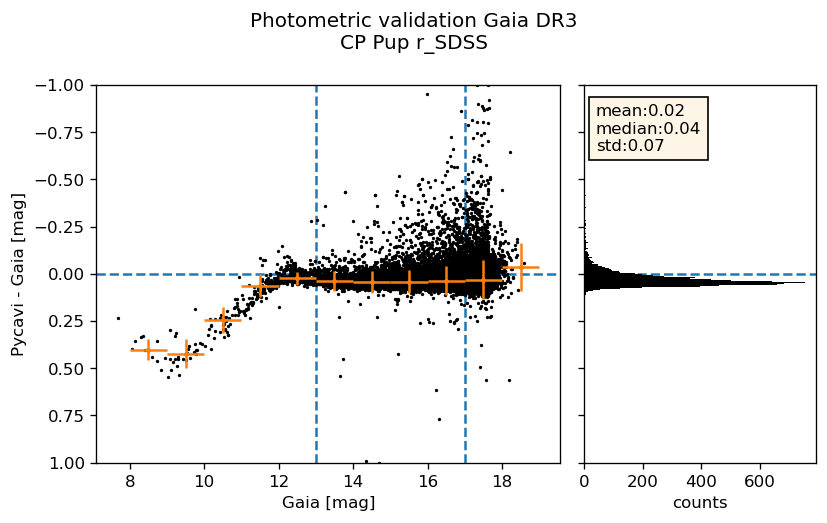

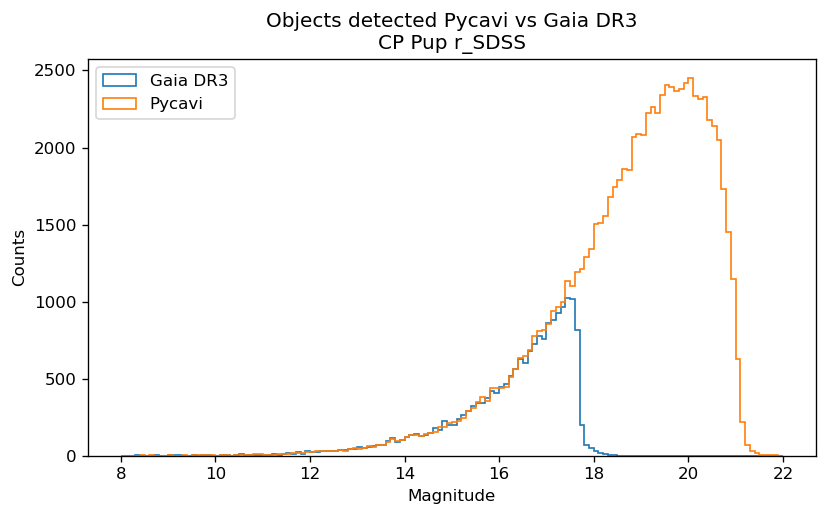

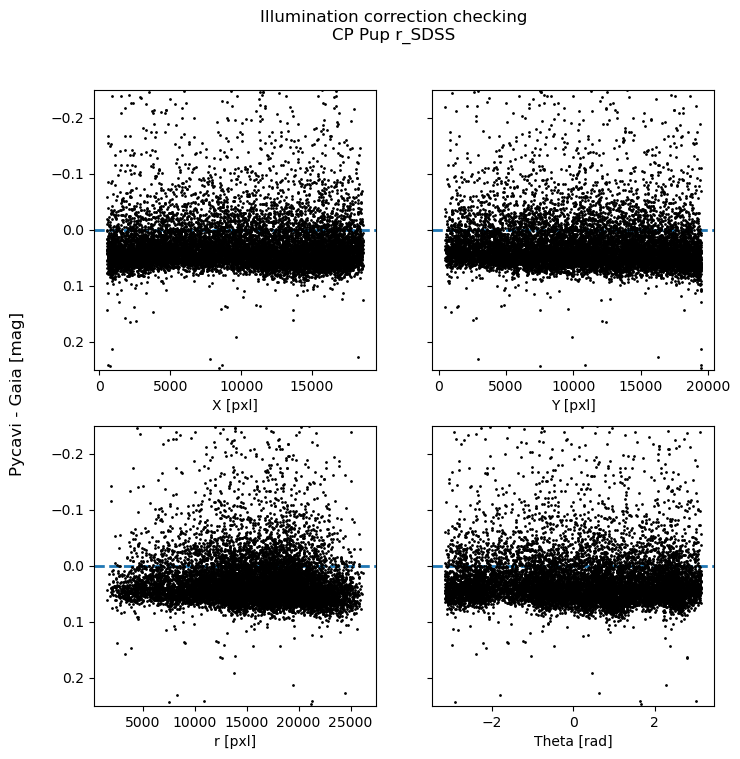

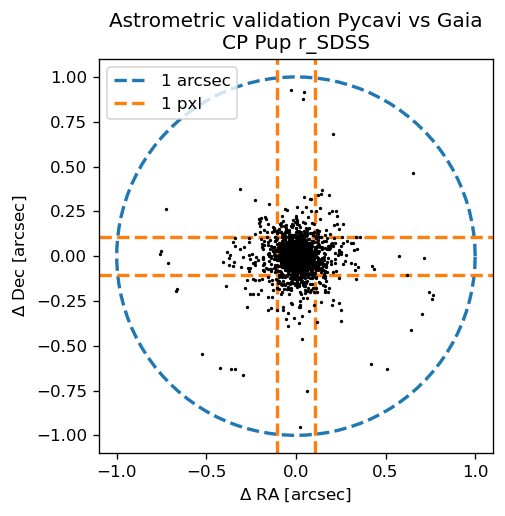

In [71]:
basedir = '/home/lceledon/Investigacion/OmegaCam/Work_dir/Calibrated_frames/CP_Pup/'
createcataloguecheckplots(basedir + 'CP_Pup_merged_catalogue_illumination_correction_kriggin.fits', band='r_SDSS')

uncorr mean: -0.049  --  median: -0.0511  --  stdev: 0.0344
corr mean: -0.0372  --  median: -0.042  --  stdev: 0.025


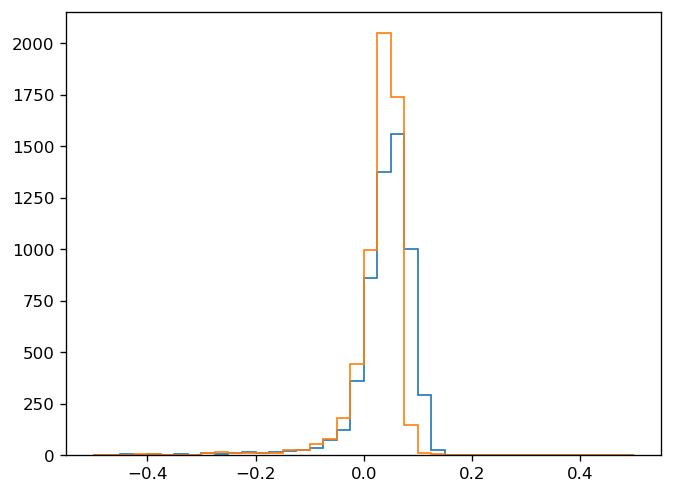

In [3]:
import matplotlib.pyplot as plt
from astropy.stats import sigma_clipped_stats

mag_ref = load_catalogue(catalogue_path, extnumber=1, colname='r_SDSS_gaia')
mag_uncorrected = load_catalogue(catalogue_path, extnumber=1, colname='mag_petro_r_sdss')
mag_corrected = load_catalogue(basedir + 'CP_Pup_merged_catalogue_illumination_correction_kriggin_r_sdss.fits', extnumber=1, 
                               colname='mag_petro_r_sdss')

dif_uncor = mag_ref - mag_uncorrected
dif_cor = mag_ref - mag_corrected
sel = (mag_ref >= 12) & (mag_ref <= 16)

mean_uncorr, median_uncorr, std_uncorr = sigma_clipped_stats(dif_uncor[sel], sigma=3.0, maxiters=5)
mean_corr, median_corr, std_corr = sigma_clipped_stats(dif_cor[sel], sigma=3.0, maxiters=5)

print("uncorr mean: {}  --  median: {}  --  stdev: {}".format(round(mean_uncorr, 4), round(median_uncorr, 4), round(std_uncorr, 4)))
print("corr mean: {}  --  median: {}  --  stdev: {}".format(round(mean_corr, 4), round(median_corr, 4), round(std_corr, 4)))

bins=np.arange(-0.5,0.525,0.025)
fig, ax = plt.subplots(dpi=120)
ax.hist(mag_uncorrected[sel]-mag_ref[sel], bins=bins, histtype='step', label='uncorrected')
ax.hist(mag_corrected[sel]-mag_ref[sel], bins=bins, histtype='step', label='corrected')
plt.show()

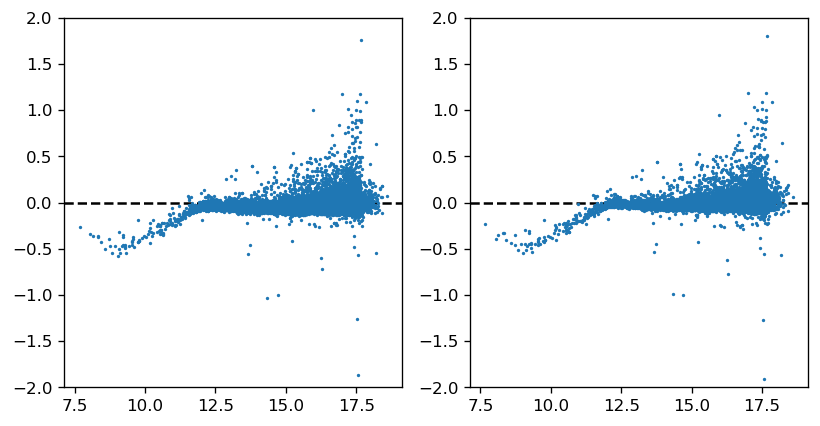

In [15]:
fig, ax = plt.subplots(figsize=(8,4), ncols=2, dpi=120)

ax[0].scatter(mag_ref, dif_uncor, s=1)
ax[1].scatter(mag_ref, dif_cor, s=1)

ax[0].axhline(0, ls='--', color='black', zorder=-1)
ax[1].axhline(0, ls='--', color='black', zorder=-1)

ax[0].set_ylim(-2, 2)
ax[1].set_ylim(-2, 2)

plt.show()

-0.04007365333520774


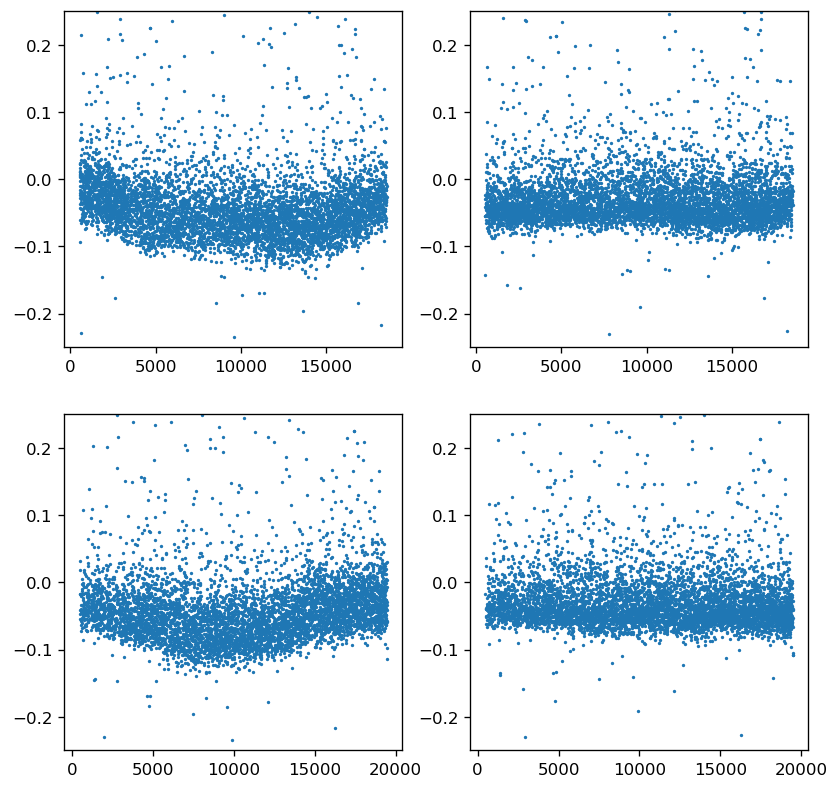

In [16]:
x_pxl = load_catalogue(catalogue_path, extnumber=1, colname='x_image_r_sdss')
y_pxl = load_catalogue(catalogue_path, extnumber=1, colname='y_image_r_sdss')

print(np.median(dif_cor[sel]))

fig, ax = plt.subplots(ncols=2, nrows=2, dpi=120, figsize=(8,8))

ax[0,0].scatter(x_pxl[sel], dif_uncor[sel], s=1)
ax[0,0].set_ylim(-0.25, 0.25)

ax[0,1].scatter(x_pxl[sel], dif_cor[sel], s=1)
ax[0,1].set_ylim(-0.25, 0.25)

ax[1,0].scatter(y_pxl[sel], dif_uncor[sel], s=1)
ax[1,0].set_ylim(-0.25, 0.25)

ax[1,1].scatter(y_pxl[sel], dif_cor[sel], s=1)
ax[1,1].set_ylim(-0.25, 0.25)

plt.show()

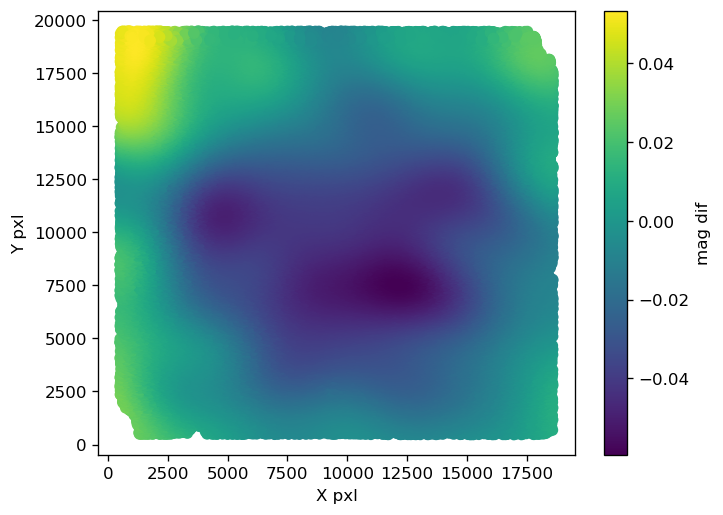

In [88]:
mag_dif = mag_corrected - mag_uncorrected

fig, ax = plt.subplots(dpi=120)
im=ax.scatter(x_pxl, y_pxl, c=mag_dif)
ax.set_xlabel('X pxl')
ax.set_ylabel('Y pxl')
fig.colorbar(im, label='mag dif')
plt.show()

In [90]:
2.5*np.log10(2.37458e-9)

-21.561032985953183

In [75]:
2.5*np.log10(2.7549e-9)

-21.39973540240835

In [74]:
plbd = 6286.0
c = 300000.0*1e3*1e10  # A/s
print(-48.574 - 2.5*np.log10(plbd**2/c))

-21.37306874660865


In [22]:
import urllib.request
import os
import pandas as pd

basedir = '/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/'
target_name = 'CP_Pup'
sm_query_name = target_name+'_sm_query.csv'
py_merged_name = target_name + '_merged_catalogue_illumination_correction_kriggin.fits'

if not os.path.isfile(sm_query_name):
    
    headers_image = fits.getheader(basedir+target_name+'_r_SDSS.coadd.fits')
    sm_query = "http://skymapper.anu.edu.au/sm-cone/public/query?RA={}&DEC={}&SR={}&VERB=3&RESPONSEFORMAT=CSV".format(headers_image['RA'], headers_image['DEC'], 1.0)
    print(sm_query)

    with urllib.request.urlopen(sm_query) as f:
        charset = f.headers.get_content_charset()
        line_list = f.read().decode(charset).split('\r\n')

    # and here we write to file
    with open(sm_query_name, "w") as f:
        for aline in line_list:
            print(aline, file=f)
            
skymapper_table = pd.read_csv(sm_query_name)
skymapper_table = Table.from_pandas(skymapper_table)

for col in skymapper_table.colnames:
    skymapper_table.rename_column(col, col+'_sm')
    
py_merged_table = load_catalogue(py_merged_name, extnumber=1)

py_sm_matched_table = crossmatch_catalogues(py_merged_table, skymapper_table, 
                                            radec_tag_1=['raj2000', 'dej2000'], 
                                            radec_tag_2=['raj2000_sm', 'dej2000_sm'])

py_sm_matched_table.write(target_name+'_merged_catalogue_illumination_correction_kriggin_skymaper.fits', format='fits', overwrite=True)

http://skymapper.anu.edu.au/sm-cone/public/query?RA=122.9462438352&DEC=-35.34568100194&SR=1.0&VERB=3&RESPONSEFORMAT=CSV


NameError: name 'pd' is not defined

In [74]:
from astropy.table import Table
from astropy.io import fits

# Create a sample Astropy Table
data = {
    'RA': [180.0, 181.0, 182.0],
    'DEC': [30.0, 31.0, 32.0],
    'Magnitude': [15.5, 16.1, 15.8]
}
table = Table(data)

# Convert the Astropy Table to a Table HDU
table_hdu = fits.BinTableHDU(table)

# Create a Primary HDU with custom headers
primary_hdu = fits.PrimaryHDU()
primary_hdu.header['author'] = 'Your Name'
primary_hdu.header['date'] = '2024-10-07'

# Combine Primary HDU and Table HDU into an HDUList
hdul = fits.HDUList([primary_hdu, table_hdu])

# Write to a FITS file
hdul.writeto('output_with_primary_headers.fits', overwrite=True)

In [83]:
with fits.open('output_with_primary_headers.fits', mode='update') as hdul:
    # Access the primary header (extension 0)
    primary_header = hdul[0].header
    
    # Modify primary headers as needed
    primary_header['newauthor'] = 'New Author'
    
    # Access the table data (extension 1) and convert it to an Astropy Table
    table_data = Table(hdul[1].data)
    
    # Modify table values as needed, e.g., adding a new column or changing values
    table_data['RA'] += 0.1  # Example: Increment all RA values by 0.1
    
    # Update the HDU with the modified table data
    hdul[1].data = table_data.as_array()